In [1]:

%pip install shap joblib pandas matplotlib scikit-learn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 544.4/544.4 kB 823.8 kB/s  0:00:00m-:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [shap]2/3 [shap]
Note: you may need to restart the kernel to use updated packages.


In [10]:

import pandas as pd
import numpy as np
import joblib
import shap
import matplotlib.pyplot as plt

from pathlib import Path

print("SHAP version:", shap.__version__)
print("Libraries imported successfully.")


SHAP version: 0.54.1
Libraries imported successfully.


In [11]:

# Load the trained Random Forest model and 2025 test results

model_path = Path("../models/kelani_next_day_threshold_rf.joblib")

results_path = Path(
    "../data/processed/kelani/"
    "kelani_next_day_threshold_predictions_2025.csv"
)

if not model_path.exists():
    raise FileNotFoundError(
        f"Model not found: {model_path}. "
        "Check the path or save the trained model first."
    )

if not results_path.exists():
    raise FileNotFoundError(
        f"2025 results not found: {results_path}. "
        "Check the path or generate the test results first."
    )

flood_model = joblib.load(model_path)
results_2025 = pd.read_csv(results_path)

print("Model loaded successfully.")
print("2025 result rows:", len(results_2025))
print("Model classes:", flood_model.classes_)

display(results_2025.head())


Model loaded successfully.
2025 result rows: 730
Model classes: ['Alert' 'Low' 'Major' 'Minor']


,Date,Next_Date,Location,Water_Level,Rainfall,Rainfall_3day,Rainfall_7day,Water_Level_Change,Next_Water_Level,Target_Severity,Predicted_Severity,Correct
0,2024-12-31,2025-01-01,Glencourse,8.629917,4.2,5.4,5.4,0.015000,8.542000,Low,Low,True
1,2025-01-01,2025-01-02,Glencourse,8.542000,16.9,21.6,22.3,-0.087917,8.492833,Low,Low,True
2,2025-01-02,2025-01-03,Glencourse,8.492833,0.5,21.6,22.8,-0.049167,8.485750,Low,Low,True
3,2025-01-03,2025-01-04,Glencourse,8.485750,0.0,17.4,22.8,-0.007083,8.525333,Low,Low,True
4,2025-01-04,2025-01-05,Glencourse,8.525333,0.0,0.5,22.8,0.039583,8.436167,Low,Low,True


In [12]:

# Select only the six features used during model training

features = [
    "Location",
    "Water_Level",
    "Rainfall",
    "Rainfall_3day",
    "Rainfall_7day",
    "Water_Level_Change"
]

missing = set(features) - set(results_2025.columns)

if missing:
    raise ValueError(f"Missing model features: {missing}")

X_explain = results_2025[features].copy()

# Clean missing values in model inputs
X_explain = X_explain.dropna().copy()

if X_explain.empty:
    raise ValueError("No complete rows are available for SHAP.")

print("Rows available for explanation:", len(X_explain))
display(X_explain.head())


Rows available for explanation: 730


,Location,Water_Level,Rainfall,Rainfall_3day,Rainfall_7day,Water_Level_Change
0,Glencourse,8.629917,4.2,5.4,5.4,0.015000
1,Glencourse,8.542000,16.9,21.6,22.3,-0.087917
2,Glencourse,8.492833,0.5,21.6,22.8,-0.049167
3,Glencourse,8.485750,0.0,17.4,22.8,-0.007083
4,Glencourse,8.525333,0.0,0.5,22.8,0.039583


In [13]:

# Extract the preprocessing and Random Forest steps

preprocessor = flood_model.named_steps["preprocessor"]
rf_model = flood_model.named_steps["classifier"]

X_transformed = preprocessor.transform(X_explain)

if hasattr(X_transformed, "toarray"):
    X_transformed = X_transformed.toarray()

feature_names = preprocessor.get_feature_names_out()

X_transformed_df = pd.DataFrame(
    X_transformed,
    columns=feature_names,
    index=X_explain.index
)

print("Transformed feature count:", len(feature_names))
print("Transformed data shape:", X_transformed_df.shape)

display(X_transformed_df.head())


Transformed feature count: 7
Transformed data shape: (730, 7)


,station__Location_Glencourse,station__Location_Hanwella,remainder__Water_Level,remainder__Rainfall,remainder__Rainfall_3day,remainder__Rainfall_7day,remainder__Water_Level_Change
0,1.0,0.0,8.629917,4.2,5.4,5.4,0.015000
1,1.0,0.0,8.542000,16.9,21.6,22.3,-0.087917
2,1.0,0.0,8.492833,0.5,21.6,22.8,-0.049167
3,1.0,0.0,8.485750,0.0,17.4,22.8,-0.007083
4,1.0,0.0,8.525333,0.0,0.5,22.8,0.039583


In [14]:

# Calculate SHAP values for the Random Forest

sample_size = min(500, len(X_transformed_df))

X_shap = X_transformed_df.sample(
    n=sample_size,
    random_state=42
)

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer(X_shap)

print("SHAP calculation completed.")
print("Input shape:", X_shap.shape)
print("SHAP values shape:", np.asarray(shap_values.values).shape)
print("Model classes:", list(rf_model.classes_))


SHAP calculation completed.
Input shape: (500, 7)
SHAP values shape: (500, 7, 4)
Model classes: ['Alert', 'Low', 'Major', 'Minor']


,Feature,Mean_Absolute_SHAP
5,remainder__Rainfall_7day,0.117837
4,remainder__Rainfall_3day,0.109654
3,remainder__Rainfall,0.054529
2,remainder__Water_Level,0.049312
6,remainder__Water_Level_Change,0.031533
0,station__Location_Glencourse,0.017139
1,station__Location_Hanwella,0.016290


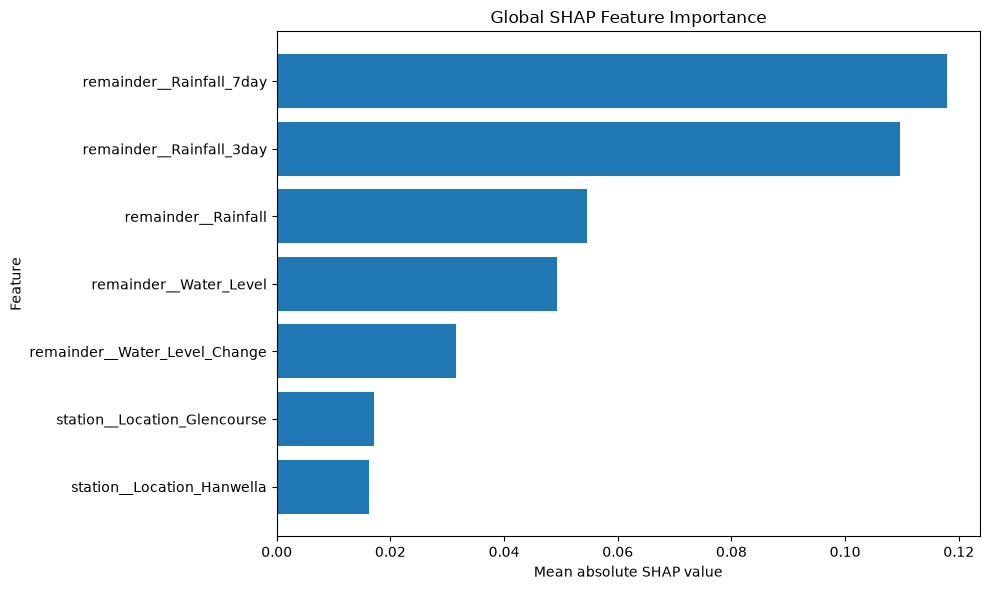

In [15]:

# Global SHAP feature importance

values = np.asarray(shap_values.values)

if values.ndim == 3:
    # Shape: observations × features × classes
    importance = np.abs(values).mean(axis=(0, 2))

elif values.ndim == 2:
    # Shape: observations × features
    importance = np.abs(values).mean(axis=0)

else:
    raise ValueError(
        f"Unexpected SHAP values shape: {values.shape}"
    )

if len(importance) != len(X_shap.columns):
    raise ValueError(
        "SHAP feature count does not match transformed feature count."
    )

importance_df = pd.DataFrame({
    "Feature": X_shap.columns,
    "Mean_Absolute_SHAP": importance
}).sort_values("Mean_Absolute_SHAP", ascending=False)

display(importance_df)

plt.figure(figsize=(10, 6))
plot_df = importance_df.sort_values("Mean_Absolute_SHAP")

plt.barh(
    plot_df["Feature"],
    plot_df["Mean_Absolute_SHAP"]
)

plt.xlabel("Mean absolute SHAP value")
plt.ylabel("Feature")
plt.title("Global SHAP Feature Importance")
plt.tight_layout()
plt.show()


Observation index: 468
Predicted severity: Low
Model probability for predicted class: 100.00%


,Location,Water_Level,Rainfall,Rainfall_3day,Rainfall_7day,Water_Level_Change
468,Hanwella,1.545,14.6,16.0,61.9,-0.245417


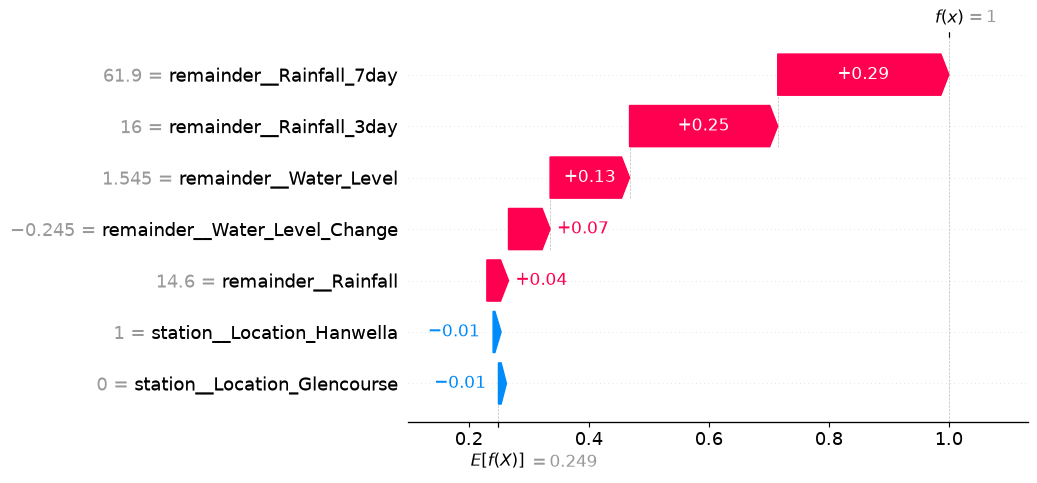

In [16]:

# Explain one individual prediction

# Recover the original input row corresponding to the sample
row_index = X_shap.index[0]
one_row = X_explain.loc[[row_index]]

predicted_class = flood_model.predict(one_row)[0]
probabilities = flood_model.predict_proba(one_row)[0]

class_index = list(rf_model.classes_).index(predicted_class)

print("Observation index:", row_index)
print("Predicted severity:", predicted_class)
print(
    "Model probability for predicted class:",
    f"{probabilities[class_index] * 100:.2f}%"
)

display(one_row)

# Explain the transformed observation
one_transformed_df = X_shap.loc[[row_index]]
one_shap = explainer(one_transformed_df)

values = np.asarray(one_shap.values)
base_values = np.asarray(one_shap.base_values)

# Select the predicted class from the multiclass explanation
if values.ndim == 3:
    one_values = values[0, :, class_index]
else:
    one_values = values[0]

if base_values.ndim == 2:
    one_base = base_values[0, class_index]
else:
    one_base = base_values.reshape(-1)[0]

one_explanation = shap.Explanation(
    values=one_values,
    base_values=one_base,
    data=one_transformed_df.iloc[0].to_numpy(),
    feature_names=list(one_transformed_df.columns)
)

shap.plots.waterfall(one_explanation, max_display=15)
plt.show()


In [17]:

# Save the global SHAP feature importance table

output_path = Path(
    "../data/processed/kelani/"
    "kelani_shap_global_feature_importance.csv"
)

output_path.parent.mkdir(parents=True, exist_ok=True)

importance_df.to_csv(output_path, index=False)

print("Global SHAP importance saved to:", output_path)


Global SHAP importance saved to: ../data/processed/kelani/kelani_shap_global_feature_importance.csv
